# M06-1 | 最小 QAT：prepared 的 QAT 圖就是普通的 GraphModule，直接訓練

QAT 的圖長什麼樣在 M04-2 看過（conv + BN 的 QAT 子圖、fake quant 的位置）。這一章只管**訓練**。
這本 notebook 回答三件事：prepared 的圖能不能 backward、訓練迴圈要多做什麼、convert 之後和 PTQ 一不一樣。

- **A.** STE：fake quant 裡的 round 沒有梯度，backward 時怎麼辦。
- **B.** 最小訓練迴圈：`export(train=True)` → `prepare_qat_pt2e` → 每個 epoch 切 train／eval → 訓練。
- **C.** convert：圖和 PTQ 同形；fp32、PTQ、QAT 的 accuracy 與 test loss。

STE 為什麼必要、怎麼推導，見作者的文章
[搞懂 Quantization Aware Training 中的 Fake Quantization](https://bobondemon.github.io/2022/11/19/%E6%90%9E%E6%87%82-Quantization-Aware-Training-%E4%B8%AD%E7%9A%84-Fake-Quantization/#Fake-quantization-%E5%BF%85%E9%A0%88%E8%A6%81%E8%83%BD%E5%BE%AE%E5%88%86)。

In [1]:
import copy

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.data import calibration_batches, evaluate, evaluate_loss, make_loader, trained_tiny_net
from common.graph_utils import op_counts, qdq_nodes
from common.models import example_inputs
from common.pt2e import (
    FakeQuantize,
    MovingAverageMinMaxObserver,
    convert_pt2e,
    disable_observer,
    export_module,
    get_xnnpack_quantizer,
    move_exported_model_to_eval,
    move_exported_model_to_train,
    prepare_pt2e,
    prepare_qat_pt2e,
    quiet,
)
from common.qat import qat_quantizer
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
BLUE, MUTED = "#2a78d6", "#52514e"

## A. STE：fake quant 的梯度

一個 int8 的 `FakeQuantize`，先用 [-1, 1] 的資料校準，再 `disable_observer` 固定 range（M02-2），然後看各點的輸出與梯度：

In [2]:
fq = FakeQuantize(observer=MovingAverageMinMaxObserver, dtype=torch.int8, qscheme=torch.per_tensor_affine,
                  quant_min=-128, quant_max=127, eps=2**-12)
with torch.no_grad():
    fq(torch.linspace(-1, 1, 100))
fq.apply(disable_observer)  # 固定 range，之後的輸入不再改 scale

scale, zp = fq.calculate_qparams()
lo, hi = (fq.quant_min - int(zp)) * float(scale), (fq.quant_max - int(zp)) * float(scale)

x = torch.tensor([-3.0, -0.5, 0.0, 0.3, 0.9, 1.5, 4.0], requires_grad=True)
fq(x).sum().backward()
assert x.grad is not None
table([[f"{float(xi):+.1f}", f"{float(yi):+.4f}", f"{float(gi):.0f}", "內" if lo <= xi <= hi else "外"]
       for xi, yi, gi in zip(x, fq(x), x.grad)],
      ["x", "fq(x)", "dfq/dx", f"在 range [{lo:.2f}, {hi:.2f}] 內？"])

x,fq(x),dfq/dx,"在 range [-1.00, 1.00] 內？"
-3.0,-0.9961,0,外
-0.5,-0.5020,1,內
+0.0,+0.0000,1,內
+0.3,+0.2980,1,內
+0.9,+0.9020,1,內
+1.5,+1.0039,0,外
+4.0,+1.0039,0,外


In [3]:
inside = (x >= lo) & (x <= hi)
assert torch.equal(x.grad, inside.float())  # range 內梯度 1、外 0

把 x 掃過一段區間，畫出 forward 的輸出與 backward 的梯度：

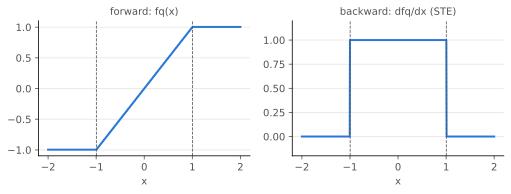

In [4]:
#| code-fold: true
#| code-summary: 畫圖的程式
xs = torch.linspace(-2, 2, 801, requires_grad=True)
ys = fq(xs)
ys.sum().backward()
assert xs.grad is not None
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.2, 2.8))
ax1.plot(xs.detach(), ys.detach(), color=BLUE, lw=2)
ax1.set_title("forward: fq(x)", color=MUTED, fontsize=10)
ax2.plot(xs.detach(), xs.grad, color=BLUE, lw=2)
ax2.set_title("backward: dfq/dx (STE)", color=MUTED, fontsize=10)
ax2.set_ylim(-0.2, 1.2)
for ax in (ax1, ax2):
    for edge in (lo, hi):
        ax.axvline(edge, color=MUTED, lw=0.8, ls="--")
    ax.set_xlabel("x", color=MUTED)
    ax.grid(axis="y", color="#e6e5e1", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
fig.tight_layout()
plt.show()

虛線是 range 的兩端。

- forward 真的做了 round 與 clamp：輸出落在 scale 的格點上，range 外被夾在邊界。int8 的格子很細，左圖看起來幾乎是直線。
- backward 把 round 當成恆等函數：range 內梯度 1、range 外 0。這就是 STE（straight-through estimator）。
- range 外的值梯度是 0，這一步得不到更新。所以 range 估太小不只是精度問題，還會讓一部分值停止學習（推論，這裡沒有另做實驗）。

QAT 能訓練靠的就是 STE。下一段直接拿 `prepare_qat_pt2e` 的圖來 backward。

## B. 最小訓練迴圈

QAT 要用 train 模式 export（`export_module(..., train=True)`，BN 才是 train 版的 op，M00-2）。
`qat_quantizer(bits=8)` 是本專案的工具（`common/qat.py`）：XNNPACKQuantizer 的 QAT 設定（per-channel weight），只把 weight 的 fake quant 換成非 fused 的版本，原因在 M06-3。現在只要知道它回傳一個 Quantizer。

In [5]:
model = trained_tiny_net()
test_loader = make_loader(n=1024, seed=2, shuffle=False)

gm = export_module(copy.deepcopy(model), example_inputs(), train=True)
prepared = prepare_qat_pt2e(gm, qat_quantizer(bits=8))

params = dict(prepared.named_parameters())
fq_names = [n.target for n in prepared.graph.nodes if n.op == "call_module" and "activation_post_process" in n.target]
fq_params = sum(p.numel() for n in fq_names for p in prepared.get_submodule(n).parameters())
print(f"prepared 圖的參數：{len(params)} 個 tensor，例如 {list(params)[:3]}")
print(f"fake quant 模組 {len(fq_names)} 個，它們的參數數：{fq_params}")
assert fq_params == 0 and all(not n.startswith("activation_post_process") for n in params)

prepared 圖的參數：14 個 tensor，例如 ['stem.conv.weight', 'stem.bn.weight', 'stem.bn.bias']
fake quant 模組 16 個，它們的參數數：0


prepared 圖的參數就是原模型 conv、BN、fc 的參數；fake quant 只有 buffer（min／max／scale），沒有參數，所以 optimizer 不會動到 scale（M06-5 的 `LearnableFakeQuantize` 才會）。

訓練迴圈和一般的 PyTorch 迴圈只差兩行：export 之後的圖沒有 `.train()`／`.eval()` 的語意（M00-2），BN 的 `training` 寫在 node 的參數裡，要用 `move_exported_model_to_train`／`move_exported_model_to_eval` 改圖。

In [6]:
def train_qat_minimal(prepared, epochs=3, lr=1e-3):
    """最小 QAT 迴圈：每個 epoch 開頭切 train、結尾切 eval。回傳每個 epoch 的 (train loss, test loss)。"""
    loader = make_loader(n=1024, seed=1)
    opt = torch.optim.SGD(prepared.parameters(), lr=lr, momentum=0.9)
    lossf = torch.nn.CrossEntropyLoss()
    history, loss = [], torch.zeros(())
    for _ in range(epochs):
        move_exported_model_to_train(prepared)  # BN 用 batch 統計
        for xb, yb in loader:
            opt.zero_grad()
            loss = lossf(prepared(xb), yb)
            loss.backward()  # fake quant 走 STE，梯度照常傳到 conv／fc 的 weight
            opt.step()
        move_exported_model_to_eval(prepared)  # 評估時 BN 用 running stats
        history.append((float(loss), evaluate_loss(prepared, test_loader)))
    return history


history = train_qat_minimal(prepared)
table([[ep, f"{tr:.4f}", f"{te:.4f}"] for ep, (tr, te) in enumerate(history)],
      ["epoch", "最後一個 batch 的 train loss", "test loss（eval 模式）"])

epoch,最後一個 batch 的 train loss,test loss（eval 模式）
0,0.0164,0.8369
1,0.0075,0.8348
2,0.0085,0.8313


- prepared 的 QAT 圖是普通的 GraphModule：optimizer 吃 `prepared.parameters()`，`loss.backward()` 照常。
- lr 用 1e-3，是 fp32 訓練（1e-2）的十分之一：QAT 是微調，起點已經是訓練好的模型。
- 這裡的 test loss 是在 observer 還開著時算的；評估前其實還要關掉 observer，M06-2 說明原因。

之後的 notebook 改用 `common/qat.py` 的 `train_qat()`，迴圈內容相同，多了一個每個 step 都會呼叫的 hook（M06-5 用它在中途打開 range learning）。

## C. convert：和 PTQ 的圖對照，以及精度

評估與 convert 前先 `disable_observer`（M06-2）。對照組有兩個：

- **PTQ int8**：同一個模型走 M05 的 PTQ。
- **fp32 再訓練 3 epochs**：同樣的迴圈、不插 fake quant，直接訓練 export 的 train 圖。

In [7]:
prepared.apply(disable_observer)
qat_int8 = convert_pt2e(copy.deepcopy(prepared))

ptq_prepared = prepare_pt2e(export_module(copy.deepcopy(model), example_inputs()), get_xnnpack_quantizer(is_per_channel=True)[0])
with torch.no_grad():
    for batch in calibration_batches(128):
        ptq_prepared(*batch)
ptq_int8 = convert_pt2e(ptq_prepared)

retrained = export_module(copy.deepcopy(model), example_inputs(), train=True)
_ = train_qat_minimal(retrained)

c_qat, c_ptq = op_counts(qat_int8), op_counts(ptq_int8)
table([["batch_norm", c_ptq.get("batch_norm", 0), c_qat.get("batch_norm", 0)],
       ["conv2d", c_ptq.get("conv2d", 0), c_qat.get("conv2d", 0)],
       ["q/dq node", len(qdq_nodes(ptq_int8)), len(qdq_nodes(qat_int8))]],
      ["", "PTQ int8", "QAT int8"])

,PTQ int8,QAT int8
batch_norm,0,0
conv2d,4,4
q/dq node,28,28


In [8]:
assert c_qat == c_ptq  # op 組成完全相同

兩條路徑呼叫的是同一個 `convert_pt2e`，它沒有 `is_qat` 參數：先把 observer／fake quant 換成 q/dq，再嘗試比對 QAT 的 conv + BN 子圖（M02-3 的五步、M04-2）。
PTQ 的 BN 在 prepare 時已經折掉，這一步什麼都不做；QAT 的子圖比對成功，BN 在這一步才折進 conv。所以兩者最後同形，後端分不出來。

精度：

In [9]:
models = {"fp32": model, "fp32 再訓練 3 epochs（不量化）": retrained, "PTQ int8": ptq_int8, "QAT int8": qat_int8}
results = {name: (evaluate(m, test_loader), evaluate_loss(m, test_loader)) for name, m in models.items()}
table([[name, f"{acc:.4f}", f"{loss:.4f}"] for name, (acc, loss) in results.items()],
      ["模型", "accuracy（1024 筆）", "test loss"])

模型,accuracy（1024 筆）,test loss
fp32,0.7109,0.8263
fp32 再訓練 3 epochs（不量化）,0.7119,0.8273
PTQ int8,0.7051,0.8284
QAT int8,0.7178,0.8332


In [10]:
losses = [loss for _, loss in results.values()]
assert max(losses) - min(losses) < 0.01

- **指標改用 test loss**：QAT 會改 weight，M05 的「對原 fp32 輸出的 SQNR」量的是「離原模型多遠」，不是「量化後好不好」。test loss 連續，而且是 QAT 直接最佳化的量。
- **比較對象是「再訓練、不量化」那一個 row**：QAT 多做了「訓練」這件事。要分開訓練本身與量化的影響，基準要用同樣配方再訓練的 fp32，不是原 fp32。
- **int8 沒有東西可救**：四個 row 的 test loss 相差不到 0.01，單一 seed 分不出高下。PTQ int8 已經貼著 fp32。

要看出 QAT 的效益得把位元數壓低，M06-4 改用 int4 比較。在那之前，M06-2、M06-3 先把評估做對。

## 小結

- fake quant 的 round 靠 STE 傳梯度：range 內 1、range 外 0。
- QAT 的流程：`export(train=True)` → `prepare_qat_pt2e` → 訓練（每個 epoch 切 train／eval）→ `disable_observer` → `convert_pt2e`。
- convert 之後和 PTQ 同形；int8 下 QAT 和 PTQ 的精度沒有差別。